# SETUP

## set region and contact matrix

In [1]:
#region
#use_flanders_data <- T
use_flanders_data <- "Flanders" #"Belgium", "Flanders", "Wallonia"

#contact matrix
use_cr_min15m <- F
use_cr_plus15m <- F
use_cr_plus1h <- F
use_cr_plus4h <- F
use_cr_full <- T

catch_up_d2_1995 <- T

beta_binomial <- T

## load model, functions and simulation setup


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


Loading required package: viridisLite



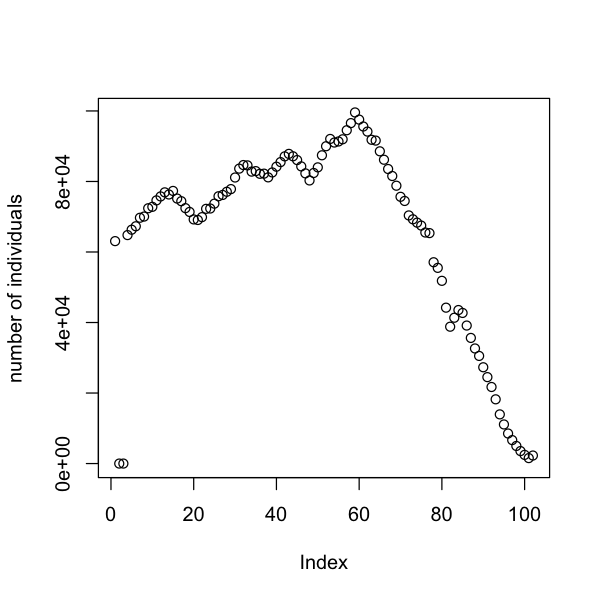

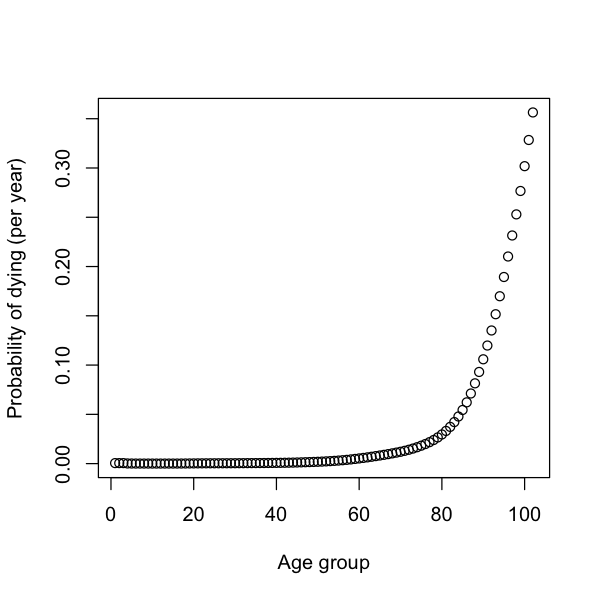

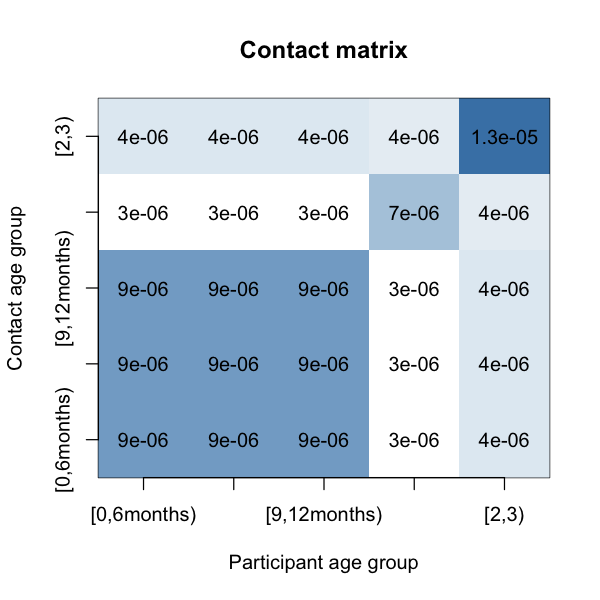

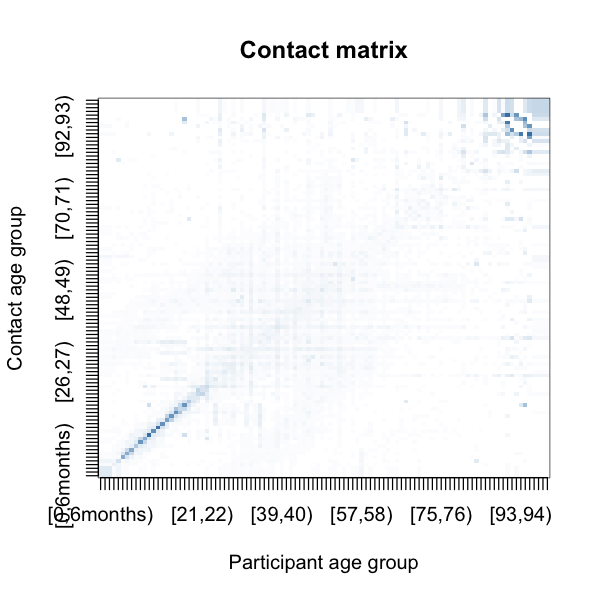

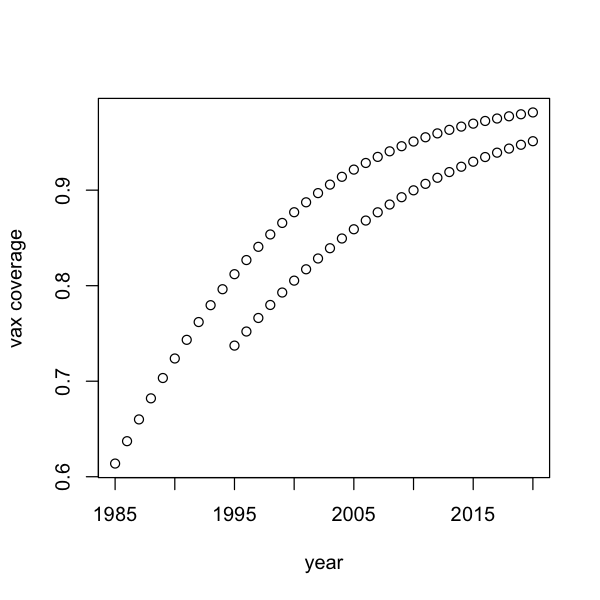

In [2]:
source("src/common-functions.R")
source("src/data-setup.R")
source("src/mseirv-model.R")

## Plot fit results

In [3]:
VE_transm <- 0.5

n_intro <- 10

waning <- 0.005/365 

first_jans_per_year <- calculate_day_of_year_for_years(yts_begin, yts_end, 1, 1)
idx_start_intro <- which(yts_begin:yts_end == 1980)
start_introduction <- first_jans_per_year[idx_start_intro]

In [4]:
extract_CI <- function(df) {

    # Move rownames to a column
    df$param1 <- rownames(df)
    
    # Convert to long format + clean types
    df_long <- df %>%
      pivot_longer(
        cols = -param1,
        names_to = "param2",
        values_to = "value"
      ) %>%
      mutate(
        param1 = as.numeric(param1),
        param2 = as.numeric(param2),
        value = as.numeric(value)
      )
    
    # Find maximum (best value)
    best <- df_long[which.max(df_long$value), ]
    R0_MLE_est <- best[2] %>% pull(param2)
    ll_max <- max(df_long$value)
    
    #joint_cutoff <- ll_max - qchisq(0.95, df = 2)/2
    #joint_region <- df_long %>%
    #  filter(value >= joint_cutoff)
    #CI_R0_joint <- range(joint_region$param2)
    
    #R0_CI_lo <- CI_R0_joint[1]
    #R0_CI_up <- CI_R0_joint[2]
    
    #return(c(R0_MLE_est, R0_CI_lo, R0_CI_up))

    profile_R0 <- df_long %>%
      group_by(param2) %>%   # param2 = R0
      summarise(
        ll = max(value),
        .groups = "drop"
      )
    cutoff <- ll_max - qchisq(0.95, df = 1)/2
    CI_R0_profile <- range(
      profile_R0$param2[
        profile_R0$ll >= cutoff
      ]
    )

    R0_CI_lo <- CI_R0_profile[1]
    R0_CI_up <- CI_R0_profile[2]

    return(c(R0_MLE_est, R0_CI_lo, R0_CI_up))
}

In [5]:
df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", waning*365, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

initial_params <- c(num_age_groups, gamma, sigma, nu, NA, waning, mu, N, as.vector(cr), R0_MLE_est)
initial_params_CI_lo <- c(num_age_groups, gamma, sigma, nu, NA, waning, mu, N, as.vector(cr), R0_CI_lo)
initial_params_CI_up <- c(num_age_groups, gamma, sigma, nu, NA, waning, mu, N, as.vector(cr), R0_CI_up)

c(R0_MLE_est, R0_CI_lo, R0_CI_up)

c(initial_params[length(initial_params)], 
  initial_params_CI_lo[length(initial_params)], 
  initial_params_CI_up[length(initial_params)])

initial_params[6]*365

[1] 10.1  9.0 11.1

[1] 10.1  9.0 11.1

[1] 0.005

In [6]:
fast_waning <-  0.009/365 #   VR -> VS # Everything is expressed in rates and days. This states that one keeps an immunity for 85 years. (Life-long immunity)

df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", fast_waning*365, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

initial_params_fast_waning <- c(num_age_groups, gamma, sigma, nu, NA, fast_waning, mu, N, as.vector(cr), R0_MLE_est)
initial_params_fast_waning_CI_lo <- c(num_age_groups, gamma, sigma, nu, NA, fast_waning, mu, N, as.vector(cr),R0_CI_lo)
initial_params_fast_waning_CI_up <- c(num_age_groups, gamma, sigma, nu, NA, fast_waning, mu, N, as.vector(cr), R0_CI_up)

c(R0_MLE_est, R0_CI_lo, R0_CI_up)

c(initial_params_fast_waning[length(initial_params)], 
  initial_params_fast_waning_CI_lo[length(initial_params)], 
  initial_params_fast_waning_CI_up[length(initial_params)])

initial_params_fast_waning[6]*365

[1] 10.2  9.5 11.5

[1] 10.2  9.5 11.5

[1] 0.009

In [7]:
no_waning <-  0.000/365 #   VR -> VS # Everything is expressed in rates and days. This states that one keeps an immunity for 85 years. (Life-long immunity)

df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", no_waning*365, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

initial_params_no_waning <- c(num_age_groups, gamma, sigma, nu, NA, no_waning, mu, N, as.vector(cr), R0_MLE_est)
initial_params_no_waning_CI_lo <- c(num_age_groups, gamma, sigma, nu, NA, no_waning, mu, N, as.vector(cr),R0_CI_lo)
initial_params_no_waning_CI_up <- c(num_age_groups, gamma, sigma, nu, NA, no_waning, mu, N, as.vector(cr), R0_CI_up)

c(R0_MLE_est, R0_CI_lo, R0_CI_up)

c(initial_params_no_waning[length(initial_params)], 
  initial_params_no_waning_CI_lo[length(initial_params)], 
  initial_params_no_waning_CI_up[length(initial_params)])

initial_params_no_waning[6]

[1]  9.6  8.1 10.6

[1]  9.6  8.1 10.6

[1] 0

# SCENARIOS

## Timesteps for events

In [8]:
# SCENARIOS ################

## Timesteps for model simulation, RAS and vaccination #####
yts_begin <- 1940
yts_end <- 2060

# Vaccination day is 1st of September, every year
vacc_month <- 9
vacc_day <- 1
first_sept_per_year <- calculate_day_of_vaccination_for_years(yts_begin, yts_end, vacc_month, vacc_day)

vacc_month <- 3
vacc_day <- 1
first_march_per_year <- calculate_day_of_vaccination_for_years(yts_begin, yts_end, vacc_month, vacc_day)

vacc_month <- 6
vacc_day <- 1
first_june_per_year <- calculate_day_of_vaccination_for_years(yts_begin, yts_end, vacc_month, vacc_day)

# NOTE: 2nd of september!! Need to figure out how to have events on the same day...
days_of_vaccination <- cbind(first_sept_per_year+1, yts_begin:yts_end)

days_of_vaccination_6months <- cbind(first_march_per_year+1, yts_begin:yts_end)

days_of_vaccination_9months <- cbind(first_june_per_year+1, yts_begin:yts_end)

# Day everyone shifts/ages (RAS model)
# days_of_year_change <- calculate_jan1_for_years(yts_begin, yts_end)[-1] # remove first entry
days_of_year_change <- first_sept_per_year

days_of_6months_change <- first_march_per_year

days_of_9months_change <- first_june_per_year

# Time series => output waar we intresse in hebben, elke dag status van alles states 
t <- 1:calculate_days_over_years(yts_begin, yts_end)

## extend coverage beyond 2020 ######
cov1_means_extended <- c(cov1_means,rep(cov1_means[length(cov1_means)],100))  
cov2_means_extended <- c(cov2_means,rep(cov2_means[length(cov2_means)],100)) 

first_jans_per_year <- calculate_day_of_year_for_years(yts_begin, yts_end, 1, 1)
idx_start_intro <- which(yts_begin:yts_end == 1980)
start_introduction <- first_jans_per_year[idx_start_intro]

[1] 0.9813541
[1] 0.9512426


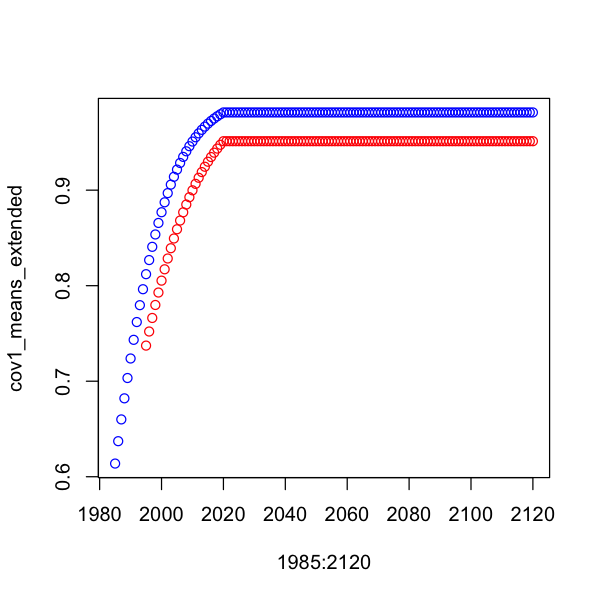

In [9]:
plot(1985:2120, cov1_means_extended, col="blue")
points(1995:2120, cov2_means_extended, col="red")
print(cov1_means_extended[length(cov1_means)])
print(cov2_means_extended[length(cov2_means)])

In [10]:
## extend coverage beyond 2020 ######

# baseline scenario
cov1_means_extended_96 <- c(cov1_means,rep(0.96,100))  # 96.1% MMR1
cov2_means_extended_93 <- c(cov2_means,rep(0.93,100))  # 93.8% MMR2

#scenarios 
cov2_means_extended_scenario95 <- c(cov2_means,rep(0.95,100)) 
cov2_means_extended_scenario89 <- c(cov2_means,rep(0.89,100)) # 89.2% MMR1+2

cov1_means_extended_scenario95 <- c(cov1_means,rep(0.95,100)) 

## Define shift programs

In [11]:
flanders_shift2023_scenario <- function(years, cov1_means, cov2_means) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year >= 2024) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

In [12]:
flanders_shift2025_scenario <- function(years, cov1_means, cov2_means) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years_shift[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2024) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2025) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2026) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2027) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2028) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2029) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year >= 2030) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(2,cov2_means[idx],'MMR2'))
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

In [13]:
flanders_shift2025_catchup30y40y_scenario <- function(years, cov1_means, cov2_means, cov1_adu_catchup) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years_shift[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2024) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2025) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     
                                                     c(30,cov1_adu_catchup,'MMR1'),
                                                     c(31,cov1_adu_catchup,'MMR1'),
                                                     c(32,cov1_adu_catchup,'MMR1'),
                                                     c(33,cov1_adu_catchup,'MMR1'),
                                                     c(34,cov1_adu_catchup,'MMR1'),
                                                     c(35,cov1_adu_catchup,'MMR1'),
                                                     c(36,cov1_adu_catchup,'MMR1'),
                                                     c(37,cov1_adu_catchup,'MMR1'),
                                                     c(38,cov1_adu_catchup,'MMR1'),
                                                     c(39,cov1_adu_catchup,'MMR1'),
                                                     c(40,cov1_adu_catchup,'MMR1'),
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2026) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2027) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2028) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2029) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year >= 2030) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(2,cov2_means[idx],'MMR2'))
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

In [14]:
flanders_shift2025_catchup30y40ytarget_scenario <- function(years, cov1_means, cov2_means, target) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years_shift[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2024) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2025) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     
                                                     c(30,(target - cov1_means[i-29])/(1-cov1_means[i-29]),'MMR1'),
                                                     c(31,(target - cov1_means[i-30])/(1-cov1_means[i-30]),'MMR1'),
                                                     c(32,(target - cov1_means[i-31])/(1-cov1_means[i-31]),'MMR1'),
                                                     c(33,(target - cov1_means[i-32])/(1-cov1_means[i-32]),'MMR1'),
                                                     c(34,(target - cov1_means[i-33])/(1-cov1_means[i-33]),'MMR1'),
                                                     c(35,(target - cov1_means[i-34])/(1-cov1_means[i-34]),'MMR1'),
                                                     c(36,(target - cov1_means[i-35])/(1-cov1_means[i-35]),'MMR1'),
                                                     c(37,(target - cov1_means[i-36])/(1-cov1_means[i-36]),'MMR1'),
                                                     c(38,(target - cov1_means[i-37])/(1-cov1_means[i-37]),'MMR1'),
                                                     c(39,(target - cov1_means[i-38])/(1-cov1_means[i-38]),'MMR1'),
                                                     c(40,(target - cov1_means[i-39])/(1-cov1_means[i-39]),'MMR1'),
                                                     c(41,(target - cov1_means[i-40])/(1-cov1_means[i-40]),'MMR1'),
                                                     
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2026) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2027) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2028) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2029) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year >= 2030) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(2,cov2_means[idx],'MMR2'))
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

In [15]:
flanders_shift2025_gradualcatchup30y40y_scenario <- function(years, cov1_means, cov2_means, cov1_adu_catchup) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years_shift[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2024) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2025) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2026) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2027) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'),  
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2028) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'),  
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2029) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'),  
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year >= 2030 & year <= 2035) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(41,cov1_adu_catchup,'MMR1'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if (year >= 2036){
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(2,cov2_means[idx],'MMR2'))
        
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

In [16]:
flanders_shift2025_scenario_9months <- function(years, cov1_means, cov2_means) {
  if (length(years) > length(cov1_means)) {
    raise_error
  }
  age_cat_to_vacc <- list()
  for(i in 1:length(years)) {
    year <- years_shift[i]
    if(year >= 1995 & year <= 2022) { # no shift yet, regular schedule
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'))
      if (year == 1995) {
          if (catch_up_d2_1995 == T) {
          age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i], 'MMR1'), 
                                                         c(10,cov2_means[idx],'MMR2'),
                                                         c(11,cov2_means[idx],'MMR2'))              
          }
      }
    } else if(year == 2023) { # implement shift, start catch up 
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(10,cov2_means[idx],'MMR2'),
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2024) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(1,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'))
    } else if(year == 2025) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2026) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(9,cov2_means[idx],'MMR2'),
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2027) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2028) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year == 2029) {
      idx <- i -10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(7,cov2_means[idx],'MMR2'),
                                                     c(2,cov2_means[idx],'MMR2'))
    } else if(year >= 2030) {
      idx <- i - 10
      age_cat_to_vacc[[as.character(year)]] <- rbind(c(0.75,cov1_means[i],'MMR1'), 
                                                     c(2,cov2_means[idx],'MMR2'))
    } else { # geboorte jaren incl 1994 en lager
      age_cat_to_vacc[[as.character(year)]] <- c(1,cov1_means[i],'MMR1') # only vaccinate with first dose at 1 y.o.
    }
  }
  return(age_cat_to_vacc)
}

## Apply shift programs

In [17]:
### apply shift programs ######
years_shift <- 1985:yts_end

# baseline, no shift to 2y
age_cat_to_vacc_shift_2023 <- flanders_shift2023_scenario(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_93)

# shift to 2y, stable coverage
age_cat_to_vacc_shift_2025 <- flanders_shift2025_scenario(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_93) 

# shift to 2y, lower coverage for d1
age_cat_to_vacc_shift_2025_lcov1 <- flanders_shift2025_scenario(years_shift, 
                                                          cov1_means_extended_scenario95, 
                                                          cov2_means_extended_93) 

# shift to 2y, higher coverage for d2
age_cat_to_vacc_shift_2025_hcov2 <- flanders_shift2025_scenario(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_scenario95) 

# shift to 2y, lower coverage for d2
age_cat_to_vacc_shift_2025_lcov2 <- flanders_shift2025_scenario(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_scenario89) 

# shift to 2y and 9 months, stable coverage
age_cat_to_vacc_shift_2025_9months <- flanders_shift2025_scenario_9months(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_93) 
# adult catchup campaigns
adu_catchup <- 0.1
age_cat_to_vacc_shift_2025_gradualcatchup30y40y_10cov <- flanders_shift2025_gradualcatchup30y40y_scenario(years_shift, 
                                                          cov1_means_extended_96, 
                                                          cov2_means_extended_93,
                                                          adu_catchup)

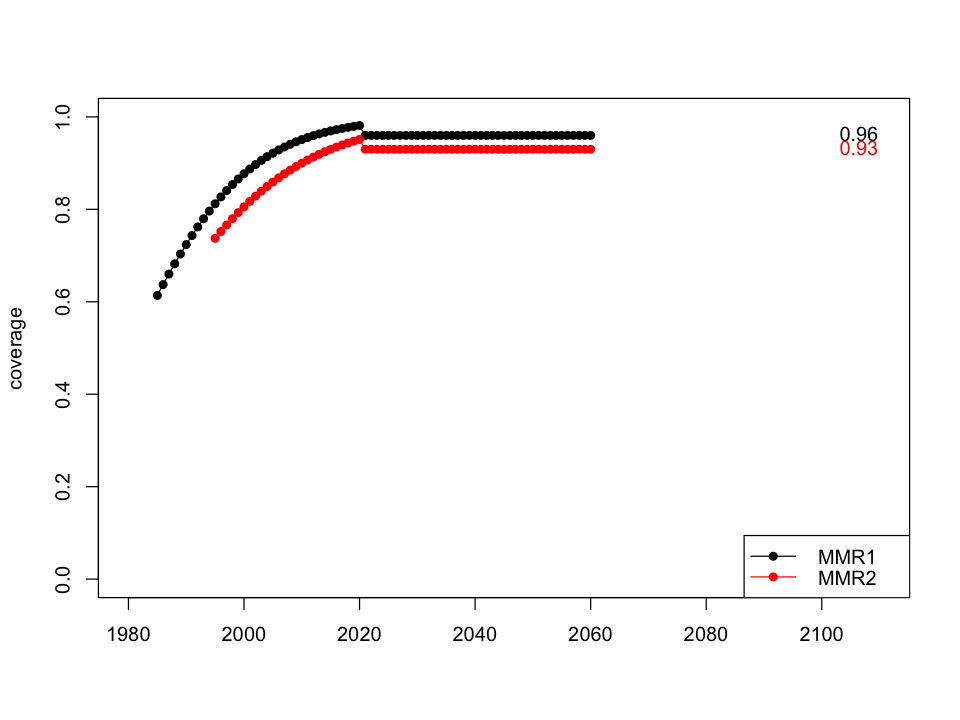

In [18]:
options(repr.plot.width = 8, repr.plot.height = 6)

years <- as.numeric(names(age_cat_to_vacc_shift_2025))

mmr1_shift <- sapply(names(age_cat_to_vacc_shift_2025), function(name) {
  x <- age_cat_to_vacc_shift_2025[[name]]
  if (is.matrix(x)) x[1, 2] else x[2]
})

mmr2_shift <- sapply(names(age_cat_to_vacc_shift_2025), function(name) {
  x <- age_cat_to_vacc_shift_2025[[name]]
  if (is.matrix(x)) x[2, 2] else NA
})

# Plot (lines + filled points)
plot(years, mmr1_shift,
     type = "o", pch = 16, lty = 1,
     col = "black",
     xlim = c(1980, 2110), ylim = c(0, 1),
     ylab = "coverage", xlab = "")

lines(years, mmr2_shift,
      type = "o", pch = 16, lty = 1,
      col = "red")


text(2101,
     round(as.numeric(mmr1_shift[['2060']]),3),
     labels = round(as.numeric(mmr1_shift[['2060']]),3),
     pos = 4,
     col = "black")

text(2101,
     round(as.numeric(mmr2_shift[['2060']]),3),
     labels = round(as.numeric(mmr2_shift[['2060']]),3),
     pos = 4,
     col = "red")

# Legend
legend("bottomright",
       legend = c("MMR1 ", "MMR2"),
       col = c("black", "red"),
       lty = c(1, 1),
       pch = 16)

## Run scenarios

### functions

In [19]:
# shortcut function to simulate scenarios differeing only in R0 and age_cat_to_vacc

simulateModel_shortcut <- function(input_initial_params, age_cat_to_vacc, immune_blunting = FALSE) {
    output <- simulateModel(t, y_init, input_initial_params, 
                              days_of_6months_change, days_of_9months_change, 
                              days_of_year_change, 
                              days_of_vaccination_6months, days_of_vaccination_9months, 
                              days_of_vaccination, 
                              age_cat_to_vacc,
                              verbose = F, disable_infections=disable_infections, t_disabling_year=t_disabling_year,
                              method = "ode45", save_newlyInf = T, 
                              VE_transm = VE_transm,
                              introductions = TRUE, start_introductions = start_introduction, n_intro = n_intro, 
                              immune_blunting = immune_blunting)

    return(output)
}

In [20]:
if (num_age_groups == 102) {
    age_groups_to_plot <- list(
      "all" = c(1:102),
      "<1" = c(1:3),
      "1-4" = c(4:7),
      "5-9" = c(8:12),
      "10-19" = c(13:22),
      "20-49" = c(23:52),
      "50+" = c(53:102)
    )
    } else {
        stop("error, please revise the definition of the age groups")
    }

In [21]:
age_cat_to_vacc <- age_cat_to_vacc_shift_2025

y_shift_2025 <- list(simulateModel_shortcut(initial_params, age_cat_to_vacc))
                     #simulateModel_shortcut(initial_params_CI_lo, age_cat_to_vacc),
                     #simulateModel_shortcut(initial_params_CI_up, age_cat_to_vacc))

y_shift_2025_fast_waning <- list(simulateModel_shortcut(initial_params_fast_waning, age_cat_to_vacc))
                     #simulateModel_shortcut(initial_params_fast_waning_CI_lo, age_cat_to_vacc),
                     #simulateModel_shortcut(initial_params_fast_waning_CI_up, age_cat_to_vacc))

y_shift_2025_no_waning <- list(simulateModel_shortcut(initial_params_no_waning, age_cat_to_vacc))
                     #simulateModel_shortcut(initial_params_no_waning_CI_lo, age_cat_to_vacc),
                     #simulateModel_shortcut(initial_params_no_waning_CI_up, age_cat_to_vacc))

In [22]:
# test for Laura Cornelissen with lower coverage for D1 from 2010
cov1_means_extended_89_from_2015 <- c(cov1_means[1:30], rep(0.89,100))
cov2_means_extended_89_from_2015 <- c(cov2_means[1:20], rep(0.89,100))

# shift to 2y, lower coverage for d2 and for d1
age_cat_to_vacc_shift_2025_lcov2_lcov1_2010 <- flanders_shift2025_scenario(years_shift, 
                                                          cov1_means_extended_89_from_2015, 
                                                          cov2_means_extended_89_from_2015)

y_shift_2025_TEST_historiallowcov1 <- list(simulateModel_shortcut(initial_params_no_waning, 
                                                      age_cat_to_vacc_shift_2025_lcov2_lcov1_2010))

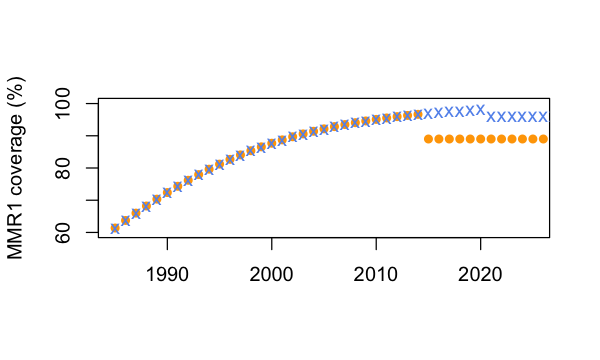

In [23]:
options(repr.plot.width = 5, repr.plot.height = 3)

plot(c(1:length(cov1_means_extended_89_from_2015))+1984,
     100*cov1_means_extended_89_from_2015, col="orange", 
     xlim = c(1985, 2025), ylim = c(60,100),
     pch=16,
     xlab = NA, ylab = "MMR1 coverage (%)")

points(c(1:length(cov1_means_extended_96))+1984,
     100*cov1_means_extended_96, col="cornflowerblue", 
     xlim = c(1985, 2025), ylim = c(60,100),
     pch=120)

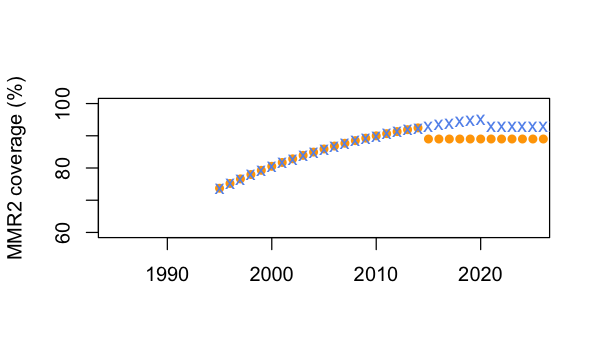

In [24]:
options(repr.plot.width = 5, repr.plot.height = 3)
plot(c(1:length(cov2_means_extended_89_from_2015))+1994, 
     100*cov2_means_extended_89_from_2015, col="orange", 
     xlim = c(1985, 2025), ylim = c(60,100),
     pch=16,
     xlab = NA, ylab = "MMR2 coverage (%)")
points(c(1:length(cov2_means_extended_93))+1994,
     100*cov2_means_extended_93, col="cornflowerblue", 
     xlim = c(1985, 2025), ylim = c(60,100),
     pch=120)

In [25]:
library(parallel)

# Define scenarios
scenarios <- list(
  y_shift_2023 = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2023,
    immune_blunting = FALSE
  ),
  y_shift_2025_lcov1 = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_lcov1,
    immune_blunting = FALSE
  ),
  y_shift_2025_hcov2 = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_hcov2,
    immune_blunting = FALSE
  ),
  y_shift_2025_lcov2 = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_lcov2,
    immune_blunting = FALSE
  ),
  y_shift_2025_9months = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_9months,
    immune_blunting = FALSE
  ),
  y_shift_2025_9months_immune_blunting = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_9months,
    immune_blunting = TRUE
  ),
  y_shift_2025_gradualcatchup30y40y_cov10 = list(
    age_cat_to_vacc = age_cat_to_vacc_shift_2025_gradualcatchup30y40y_10cov,
    immune_blunting = FALSE
  )
)

# Number of cores
#ncores <- max(1, detectCores() - 1)
ncores <- 10

# Run in parallel
start_time <- Sys.time()

results <- mclapply(
  scenarios,
  function(x) {
    list(
      simulateModel_shortcut(
        initial_params,
        x$age_cat_to_vacc,
        immune_blunting = x$immune_blunting
      )
    )
  },
  mc.cores = ncores
)

In [26]:
elapsed <- Sys.time() - start_time
cat("Elapsed time:", elapsed, "\n")

# Assign results back to individual objects
list2env(results, envir = .GlobalEnv)

Elapsed time: 45.77045 


<environment: R_GlobalEnv>

### sample from CI

In [27]:
df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", waning*365, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

set.seed(2308)
conf.level <- 0.95
crit <- qnorm(1-(1 - conf.level)/2)

if (R0_CI_up - R0_MLE_est > R0_MLE_est - R0_CI_lo) {
 sd <- (R0_CI_up - R0_MLE_est)/crit   
} else {
 sd <- (R0_MLE_est - R0_CI_lo)/crit   
}
samples_lhratio_normalapprox <- rnorm(1000, mean = R0_MLE_est, sd = sd)

samples <- samples_lhratio_normalapprox

round(quantile(samples_lhratio_normalapprox, c(0.5,0.025,0.975)),2)
round(c(initial_params[length(initial_params)], 
  initial_params_CI_lo[length(initial_params)], 
  initial_params_CI_up[length(initial_params)]),3)

50%  2.5% 97.5% 
10.12  8.99 11.15

[1] 10.1  9.0 11.1

In [28]:
df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", fast_waning*365, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

set.seed(2308)
conf.level <- 0.95
crit <- qnorm(1-(1 - conf.level)/2)

if (R0_CI_up - R0_MLE_est > R0_MLE_est - R0_CI_lo) {
 sd <- (R0_CI_up - R0_MLE_est)/crit   
} else {
 sd <- (R0_MLE_est - R0_CI_lo)/crit   
}

samples_lhratio_normalapprox_fast_waning <- rnorm(1000, mean = R0_MLE_est, sd = sd)

samples_fast_waning <- samples_lhratio_normalapprox_fast_waning

round(quantile(samples_lhratio_normalapprox_fast_waning, c(0.5,0.025,0.975)),2)
round(c(initial_params_fast_waning[length(initial_params)], 
  initial_params_fast_waning_CI_lo[length(initial_params)], 
  initial_params_fast_waning_CI_up[length(initial_params)]),3)

50%  2.5% 97.5% 
10.23  8.89 11.44

[1] 10.2  9.5 11.5

In [29]:
df <- read.csv(paste0("./results/grid_search_matrix_betabinomial_cr", cr_type, "_VE", VE_transm,
                     "_intro", n_intro, "_waning", 0, ".csv"),
               row.names = 1, check.names = FALSE)

R0_MLE_est <- extract_CI(df)[1]
R0_CI_lo <- extract_CI(df)[2]
R0_CI_up <- extract_CI(df)[3]

set.seed(2308)
conf.level <- 0.95
crit <- qnorm(1-(1 - conf.level)/2)

if (R0_CI_up - R0_MLE_est > R0_MLE_est - R0_CI_lo) {
 sd <- (R0_CI_up - R0_MLE_est)/crit   
} else {
 sd <- (R0_MLE_est - R0_CI_lo)/crit   
}

samples_lhratio_normalapprox_no_waning <- rnorm(1000, mean = R0_MLE_est, sd = sd)

samples_no_waning <- samples_lhratio_normalapprox_no_waning

round(quantile(samples_lhratio_normalapprox_no_waning, c(0.5,0.025,0.975)),2)
round(c(initial_params_no_waning[length(initial_params)], 
  initial_params_no_waning_CI_lo[length(initial_params)], 
  initial_params_no_waning_CI_up[length(initial_params)]),3)

50%  2.5% 97.5% 
 9.63  8.08 11.03

[1]  9.6  8.1 10.6

# PLOT RESULTS

## Epidemic curves

In [30]:
palette <- c("firebrick1", "cornflowerblue", "darkorchid4")

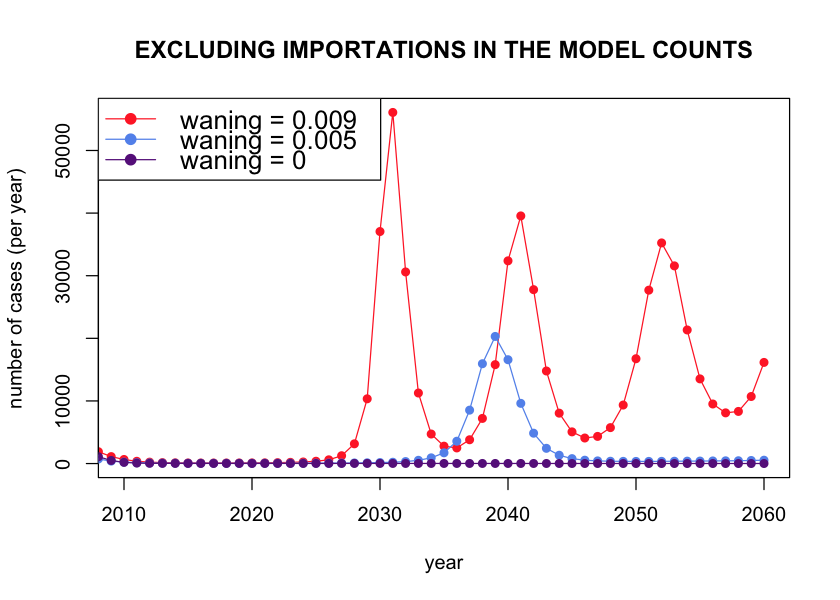

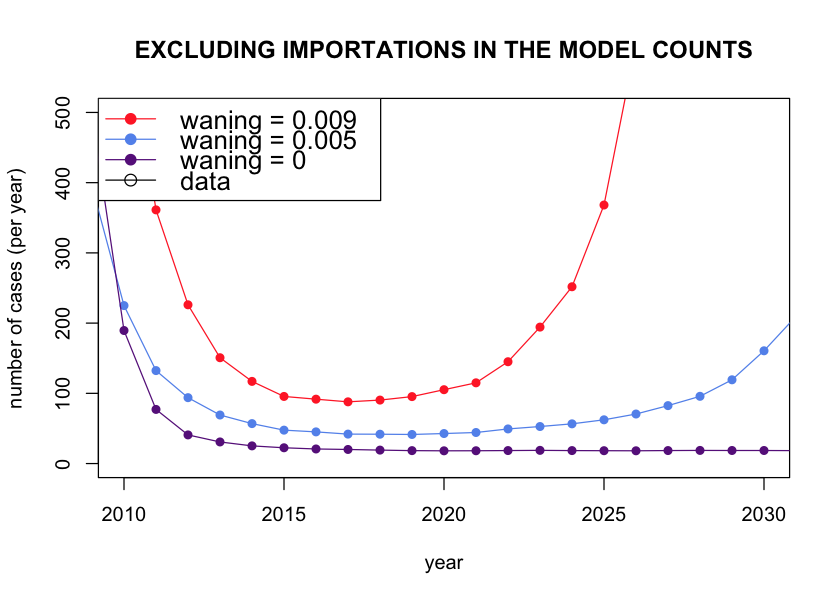

In [31]:
options(repr.plot.width = 7, repr.plot.height = 5)

# COMPUTE NUMBER OF INFECTION PER YEAR, in the model

list_year_plots <- c(2000:2060)

outbreak_shift2025 <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))
outbreak_shift2025_fast_waning <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))
outbreak_shift2025_no_waning <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))

for (i in 1:length(list_year_plots)) {
  year_plot <- list_year_plots[i]
  outbreak_shift2025[[1]][i] <- sum(calculate_newly_infectious_for_year(y_shift_2025[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
  outbreak_shift2025_fast_waning[[1]][i] <- sum(calculate_newly_infectious_for_year(y_shift_2025_fast_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
  outbreak_shift2025_no_waning[[1]][i] <- sum(calculate_newly_infectious_for_year(y_shift_2025_no_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
} 


## MAKE PLOTS

## Projection in the future
plot(list_year_plots, outbreak_shift2025_fast_waning[[1]], col=palette[1], type = "o",
     #xlim=c(2010,2040), ylim=c(0,max(outbreak_shift2025[[1]])), #log = "y",
     xlim=c(2010,2060), ylim=c(0,max(outbreak_shift2025_fast_waning[[1]])),
     main = "EXCLUDING IMPORTATIONS IN THE MODEL COUNTS",
     xlab="year", ylab="number of cases (per year)", pch=16)
lines(list_year_plots, type = "o",outbreak_shift2025[[1]], col=palette[2], pch=16)
lines(list_year_plots, type = "o",outbreak_shift2025_no_waning[[1]], col=palette[3], pch=16)

legend("topleft",
       legend = c("waning = 0.009",
                  "waning = 0.005",
                  "waning = 0"),
       col = c(palette, "black"),
       lty = 1,
       pch = c(16, 16, 16, 21),
       cex = 1.3)

## COMPARISON WITH DATA, zoom on 2010-2030
plot(list_year_plots, outbreak_shift2025_fast_waning[[1]], col=palette[1], type = "o",
     xlim=c(2010,2030), ylim=c(0,500), #log = "y",
     main = "EXCLUDING IMPORTATIONS IN THE MODEL COUNTS",
     xlab="year", ylab="number of cases (per year)", pch=16)
lines(list_year_plots, type = "o",outbreak_shift2025[[1]], col=palette[2], pch=16)
lines(list_year_plots, type = "o",outbreak_shift2025_no_waning[[1]], col=palette[3], pch=16)

legend("topleft",
       legend = c("waning = 0.009",
                  "waning = 0.005",
                  "waning = 0",
                  "data"),
       col = c(palette, "black"),
       lty = 1,
       pch = c(16, 16, 16, 21),
       cex = 1.3)

## Epidemic curves, with uncertainty

In [32]:
length(samples)

[1] 1000

In [33]:
## sortcut function to extract output of interest

extractTotalCases <- function(y_out, year_plot, selected_age_tag="all") {
    sum(calculate_newly_infectious_for_year(y_out, yts_begin, yts_end,  
                                            year_plot, age_cat_per_compartment, 
                                            selected_columns="NewlyInfectious_r", 
                                            selected_ages = age_groups_to_plot[[selected_age_tag]]))
    }

### (SKIP) run parallel simulations and save results

In [ ]:
list_year_plots <- c(2000:2060)

In [ ]:
# run the following cell to simulate the model with different R0 values sampled from the CI, and then save the results
# skip the following and read the results direcly in the next section

run_one_sample <- function(jj) {

    list_year_plots <- c(2000:2060)

    R0_sample <- samples[jj]
    
    sample_params <- initial_params
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)

    results <- numeric(length(list_year_plots))
    
    for (i in seq_along(list_year_plots)) {
        year_plot <- list_year_plots[i]
        results[i] <- extractTotalCases(y_shift_2025, year_plot, "all")
    }
    
    return(results)
}

#ncores <- detectCores() - 1   # leave one core free
ncores <- 10

out <- mclapply(
    seq_along(samples[c(1:250)]),
    run_one_sample,
    mc.cores = ncores
)

out <- as.data.frame(do.call(rbind, out))
outbreak_shift2025_uncertainty <- out

In [473]:
run_one_sample <- function(jj) {

    R0_sample <- samples_fast_waning[jj]
    
    sample_params <- initial_params_fast_waning
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)

    results <- numeric(length(list_year_plots))
    
    for (i in seq_along(list_year_plots)) {
        year_plot <- list_year_plots[i]
        results[i] <- extractTotalCases(y_shift_2025, year_plot, "all")
    }
    
    return(results)
}

#ncores <- detectCores() - 1   # leave one core free
ncores <- 10

out <- mclapply(
    seq_along(samples[c(1:250)]),
    run_one_sample,
    mc.cores = ncores
)

out <- as.data.frame(do.call(rbind, out))
outbreak_shift2025_fast_waning_uncertainty <- out

In [474]:
run_one_sample <- function(jj) {

    R0_sample <- samples_no_waning[jj]
    
    sample_params <- initial_params_no_waning
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)

    results <- numeric(length(list_year_plots))
    
    for (i in seq_along(list_year_plots)) {
        year_plot <- list_year_plots[i]
        results[i] <- extractTotalCases(y_shift_2025, year_plot, "all")
    }
    
    return(results)
}

#ncores <- detectCores() - 1   # leave one core free
ncores <- 10

out <- mclapply(
    seq_along(samples[c(1:250)]),
    run_one_sample,
    mc.cores = ncores
)

out <- as.data.frame(do.call(rbind, out))
outbreak_shift2025_no_waning_uncertainty <- out

In [40]:
save(outbreak_shift2025_uncertainty,
     outbreak_shift2025_fast_waning_uncertainty,
     outbreak_shift2025_no_waning_uncertainty,
     file = "./results/3c(updated)_Flanders_run_scenarios_Fig3b_uncertainty.RData")

### read results

In [34]:
load("./results/3c(updated)_Flanders_run_scenarios_Fig3b_uncertainty.RData")

In [35]:
dim(outbreak_shift2025_uncertainty)
dim(outbreak_shift2025_fast_waning_uncertainty)
dim(outbreak_shift2025_no_waning_uncertainty)

[1] 250  61

[1] 250  61

[1] 250  61

In [36]:
list_year_plots <- c(2000:2060)

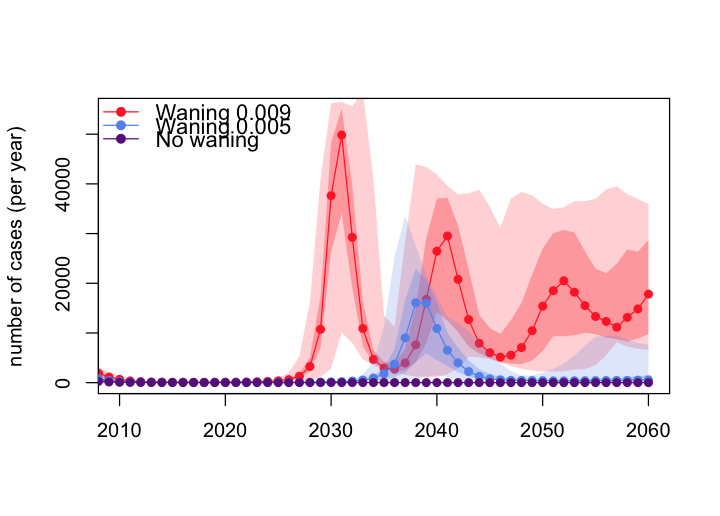

In [37]:
## Projection in the future
x <- list_year_plots

options(repr.plot.width = 6, repr.plot.height = 4.3)

out <- outbreak_shift2025_fast_waning_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)

plot(list_year_plots, medians, col=palette[1], type = "o",
     #xlim=c(2010,2040), ylim=c(0,max(outbreak_shift2025[[1]])), #log = "y",
     xlim=c(2010,2060), ylim=c(0,55000),
     #main = "EXCLUDING IMPORTATIONS IN THE MODEL COUNTS",
     xlab="", ylab="number of cases (per year)", pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[1], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[1], alpha.f = 0.3),
        border = NA)

out <- outbreak_shift2025_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)
lines(list_year_plots, type = "o", medians, col=palette[2], pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[2], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[2], alpha.f = 0.3),
        border = NA)

out <- outbreak_shift2025_no_waning_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)
lines(list_year_plots, type = "o", medians, col=palette[3], pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[3], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[3], alpha.f = 0.3),
        border = NA)

legend("topleft",
       legend = c("Waning 0.009",
                  "Waning 0.005",
                  "No waning"),
       col = c(palette, "black"),
       lty = 1,
       pch = c(16, 16, 16),
       cex = 1.1, 
       y.intersp = 1.,
       bty = "n")

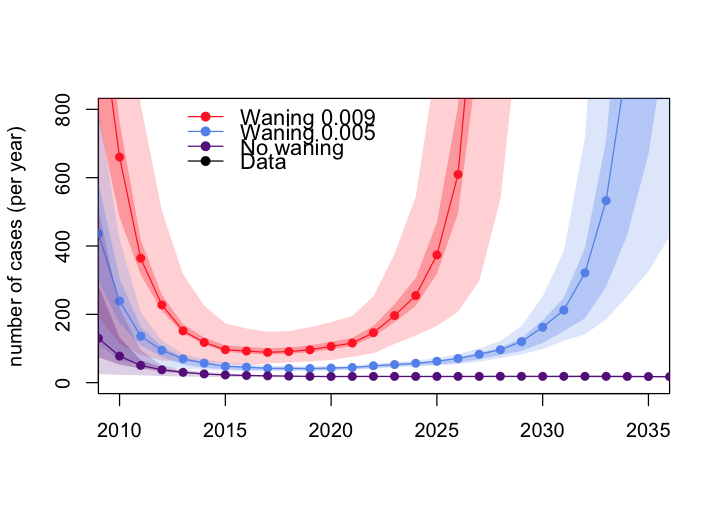

In [38]:
## COMPARISON WITH DATA, zoom on 2010-2030

options(repr.plot.width = 6, repr.plot.height = 4.3)

out <- outbreak_shift2025_fast_waning_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)

plot(list_year_plots, medians, col=palette[1], type = "o",
     xlim=c(2010,2035), ylim=c(0,800), #log = "y",
     #main = "EXCLUDING IMPORTATIONS IN THE MODEL COUNTS",
     xlab="", ylab="number of cases (per year)", pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[1], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[1], alpha.f = 0.3),
        border = NA)

out <- outbreak_shift2025_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)

lines(list_year_plots, type = "o", medians, col=palette[2], pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[2], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[2], alpha.f = 0.3),
        border = NA)

out <- outbreak_shift2025_no_waning_uncertainty
medians <- apply(out, 2, median, na.rm = TRUE)
lines(list_year_plots, type = "o",medians, col=palette[3], pch=16)

y1 <- apply(out, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[3], alpha.f = 0.2),
        border = NA)

y1 <- apply(out, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(out, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(palette[3], alpha.f = 0.3),
        border = NA)

legend(x = 2013, y = 820,
       legend = c("Waning 0.009",
                  "Waning 0.005",
                  "No waning",
                  "Data"),
       col = c(palette, "black"),
       lty = 1,
       pch = c(16, 16, 16, 16),
       cex = 1.1,
       y.intersp = 1.1,
       bty = "n")

## Age distributions of infections

In [39]:
if (num_age_groups == 102) {
    age_groups_to_plot <- list("<1" = c(1:3), "1-4" = c(4:7),
                               "5-9" = c(8:12), "10-14" = c(13:17),
                               "15-19" = c(18:22), "20-24" = c(23:27),
                               "25-29" = c(28:32), "30-34" = c(33:37),
                               "35-39" = c(38:42), "40-44" = c(43:47),
                               "45-49" = c(48:52), "50-54" = c(53:57),
                               "55+" = c(58:102))
}  else {
    stop("error")
}

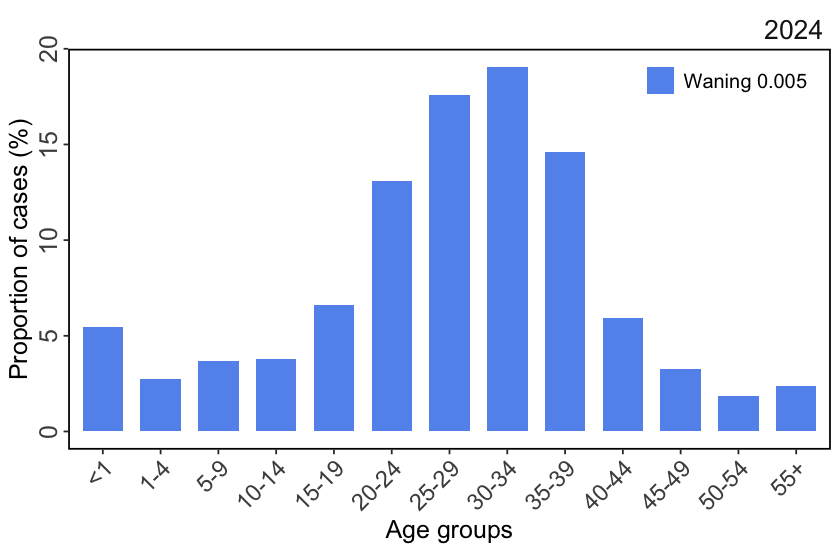

In [40]:
options(repr.plot.width = 7, repr.plot.height = 4.6)

year_groups <- rbind(c(2024, 2024))

g2 <- plot_newly_infectious_per_category_for_year_groups_list(list(y_shift_2025[[1]]), 
                                                                  dataset_labels = c("Waning 0.005"),
                                                                  yts_begin, yts_end, year_groups, 
                                                                  age_groups_to_plot, 
                                                                  age_cat_per_compartment, 
                                                                  paste(subtitle),  
                                                                  selected_columns = "NewlyInfectious_r", ## all infections
                                                                  custom_colors =  c("cornflowerblue", "#333333"), 
                                                                  show_data = FALSE)


#ggsave( "./figures/3_Flanders_figure3e.png", plot = g2, 
#       width = 7, height = 4.6, units = "in", dpi = 300)

g2

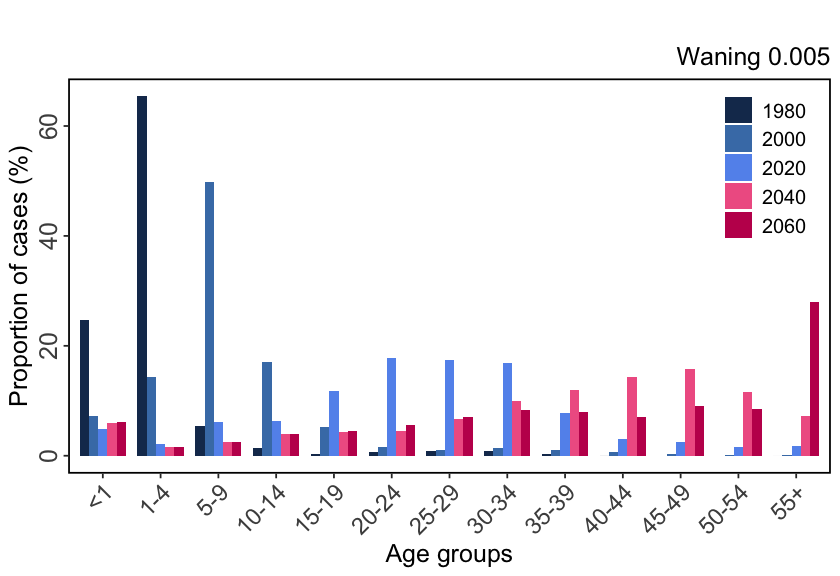

In [41]:
year_groups <- rbind(c(1980,1980),
                     c(2000,2000),
                     c(2020,2020), 
                     c(2040,2040),
                     c(2060,2060))

g2 <- plot_newly_infectious_per_category_for_year_groups(y_shift_2025[[1]], yts_begin, yts_end, year_groups, 
                                                   age_groups_to_plot, age_cat_per_compartment, 
                                                   paste("Waning 0.005"))

options(repr.plot.width = 7, repr.plot.height = 4.8)

#ggsave( "./figures/3_Flanders_figure3f.png", plot = g2, 
#       width = 7, height = 4.8, units = "in", dpi = 300)

g2

## Infections by vaccination status

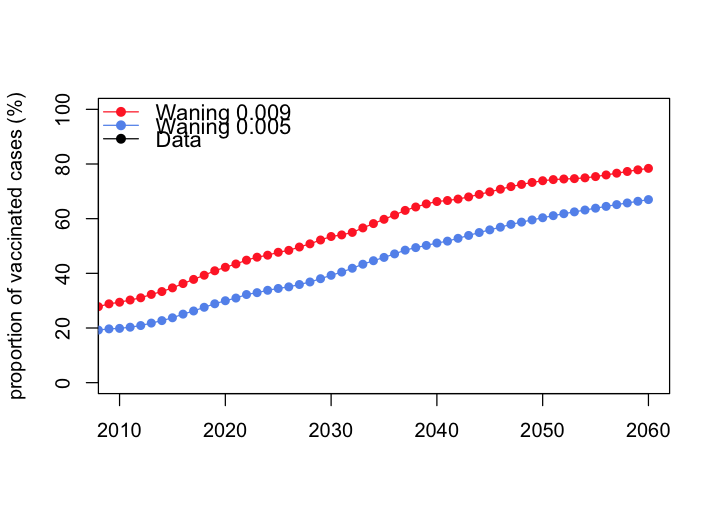

In [42]:
# COMPUTE PROPORTION OF VACCINATED INFECTIONS PER YEAR, in the model
list_year_plots <- c(2000:2060)

outbreak_shift2025 <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))
outbreak_shift2025_fast_waning <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))
outbreak_shift2025_no_waning <- list(rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)),
                           rep(0, length(list_year_plots)))

for (i in 1:length(list_year_plots)) {
  year_plot <- list_year_plots[i]
    
  total <- sum(calculate_newly_infectious_for_year(y_shift_2025[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
  unvax_cases <- sum(calculate_newly_infectious_for_year(y_shift_2025[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_dose0"))
  outbreak_shift2025[[1]][i] <- 100*(1-unvax_cases/total) 
    

  total <- sum(calculate_newly_infectious_for_year(y_shift_2025_fast_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
  unvax_cases <- sum(calculate_newly_infectious_for_year(y_shift_2025_fast_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_dose0"))
  outbreak_shift2025_fast_waning[[1]][i] <- 100*(1-unvax_cases/total) 


  total <- sum(calculate_newly_infectious_for_year(y_shift_2025_no_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_r"))
  unvax_cases <- sum(calculate_newly_infectious_for_year(y_shift_2025_no_waning[[1]], yts_begin, yts_end,  year_plot, 
                                                                   age_cat_per_compartment, selected_columns="NewlyInfectious_dose0"))
  outbreak_shift2025_no_waning[[1]][i] <- 100*(1-unvax_cases/total) 
} 


## MAKE PLOTS

options(repr.plot.width = 6, repr.plot.height = 4.3)

## Projection in the future
plot(list_year_plots, outbreak_shift2025_fast_waning[[1]], col=palette[1], type = "o",
     xlim=c(2010,2060), ylim=c(0,100),
     xlab="", ylab="proportion of vaccinated cases (%)", pch=16)
lines(list_year_plots, type = "o",outbreak_shift2025[[1]], col=palette[2], pch=16)
#lines(list_year_plots, type = "o",outbreak_shift2025_no_waning[[1]], col=palette[3], pch=16)

legend("topleft",
       legend = c("Waning 0.009",
                  "Waning 0.005",
                  #"No waning",
                  "Data"),
       col = c(palette[1:2], "black"),
       lty = 1,
       pch = c(16, 16, 16, 16),
       cex = 1.1, 
       y.intersp = 1.,
       bty = "n")

## Effective reproductive number Rt

In [43]:
compute_Rt <- function(y_output, R0, zoom_start_year, zoom_end_year) {
    
    susceptibles <- cbind(y_output[, S_r+1], 
                          y_output[, VS_r+1] + y_output[, VVS_r+1])
    colnames(susceptibles) <- c(1:(2*num_age_groups))
    
    ticks <- c()
    for (year in zoom_start_year:zoom_end_year) {
        #ticks <- rbind(ticks, calculate_jan1_for_year(yts_begin, yts_end, year))
    
        # instead of the start of the year, compute the Rt just before vaccination, when it is the highest during the year
        vacc_month <- 9
        vacc_day <- 1
        ref_day <- calculate_day_of_vaccination_for_years(yts_begin, yts_end, vacc_month, vacc_day)[which(yts_begin:yts_end == year)]
        ticks <- rbind(ticks, ref_day+1)  
    }
    
    susceptibles <- susceptibles[ticks,]
    
    red_trasm <- (1-VE_transm)
    
    Rt_output <- apply(susceptibles, 1, function(s_row) {
        # block 11, Susceptibles infected by unvaccinates individuals
          NGM_11 <- diag(s_row[1:num_age_groups] * sigma/(mu + sigma) * 1/(nu + mu)) %*% (R0*cr)
        # block 12, Susceptibles infected by vaccinates individuals
          NGM_12 <- diag(s_row[1:num_age_groups] * sigma/(mu + sigma) * 1/(nu + mu)) %*% (red_trasm*R0*cr)
        # block 21, Susceptibles Vaccinated infected by unvaccinates individuals
          NGM_21 <- diag(s_row[(num_age_groups+1):(2*num_age_groups)] * sigma/(mu + sigma) * 1/(nu + mu)) %*% (R0*cr)
        # block 12, Susceptibles Vaccinated infected by vaccinates individuals
          NGM_22 <- diag(s_row[(num_age_groups+1):(2*num_age_groups)] * sigma/(mu + sigma) * 1/(nu + mu)) %*% (red_trasm*R0*cr)
          NGM <- rbind(cbind(NGM_11,  NGM_12),
                       cbind(NGM_21,  NGM_22)) 
          max(Re(eigen(NGM)$values))
    })

    Rt_output
}

In [44]:
zoom_start_year <- 2000
zoom_end_year <- 2060

Rt_shift2025 <- compute_Rt(y_shift_2025[[1]], 
                   initial_params[length(initial_params)], 
                   zoom_start_year, zoom_end_year)

Rt_shift2025_fast_waning <- compute_Rt(y_shift_2025_fast_waning[[1]], 
                   initial_params_fast_waning[length(initial_params)], 
                   zoom_start_year, zoom_end_year)

Rt_shift2025_no_waning <- compute_Rt(y_shift_2025_no_waning[[1]], 
                   initial_params_no_waning[length(initial_params)], 
                   zoom_start_year, zoom_end_year)

In [45]:
df <- data.frame(year = zoom_start_year:zoom_end_year, 
                 Rt = Rt_shift2025_fast_waning, 
                 scenario = "Waning 0.009")

df <- rbind(df, data.frame(year = zoom_start_year:zoom_end_year, 
                 Rt = Rt_shift2025, 
                 scenario = "Waning 0.005"))

df <- rbind(df, data.frame(year = zoom_start_year:zoom_end_year, 
                 Rt = Rt_shift2025_no_waning, 
                 scenario = "No waning"))

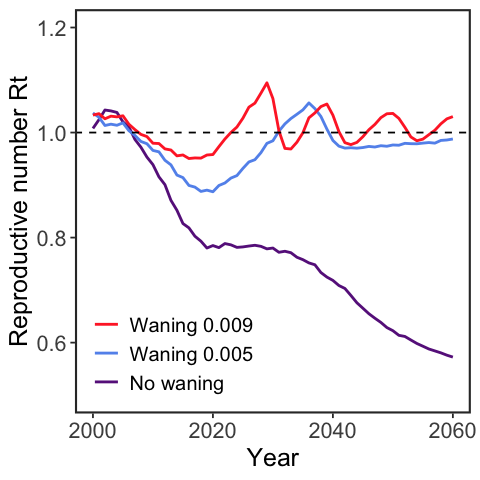

In [46]:
options(repr.plot.width = 4, repr.plot.height = 4)

pp <- ggplot(df, aes(x = year, y = Rt, color = scenario, group = scenario)) +
  geom_line(linewidth = 0.8) +
  geom_hline(yintercept = 1, color = "black", linetype = "dashed") +
  scale_color_manual(
    values = palette[1:3],
    breaks = c("Waning 0.009", "Waning 0.005", "No waning")
  ) +
  coord_cartesian(ylim = c(0.5, 1.2)) +
  labs(
    x = "Year",
    y = "Reproductive number Rt",
    color = NULL
  ) +
  theme_bw() +
  theme(
    axis.text = element_text(size = 13),
    axis.title = element_text(size = 15),
    legend.position = c(0.02, 0.02),
    legend.justification = c(0, 0),
    legend.text = element_text(size = 12),
    legend.background = element_blank(),
    panel.grid = element_blank(),
    panel.border = element_rect(linewidth = 1.2)
  )

#ggsave( "./figures/3_Flanders_figure3c.png", plot = pp, 
#       width = 4, height = 4, units = "in", dpi = 300)

pp

## Overall immunity

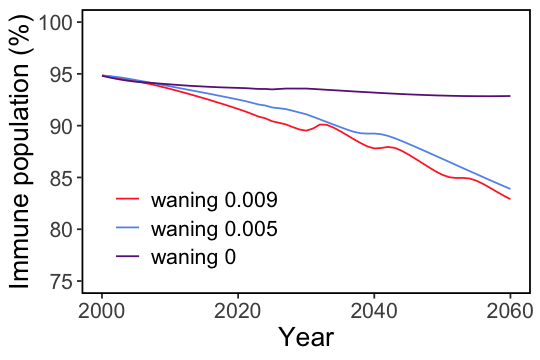

In [47]:
options(repr.plot.width = 4.5, repr.plot.height = 3)

df_susceptibility_perc <- prepare_susceptibility_percentages_normal_vs_shift(y_shift_2025_fast_waning[[1]], "waning 0.009",
                                                                             list(y_shift_2025[[1]],
                                                                                 y_shift_2025_no_waning[[1]]),
                                                                             c("waning 0.005",
                                                                               "waning 0"),
                                                                             yts_begin, yts_end, 2000, 2060, 2, 1, 
                                                                             age_cat_per_compartment)

plot_susceptibility_percentages_normal_vs_shift(df_susceptibility_perc, paste(subtitle))

## overall immunity, with uncertainty

### (SKIP) run parallel simulations and save results

In [70]:
library(parallel)

In [105]:
run_one_sample <- function(jj) {

    R0_sample <- samples_lhratio_normalapprox[jj]
    
    sample_params <- initial_params
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)


    R0_sample <- samples_lhratio_normalapprox_fast_waning[jj]
    
    sample_params <- initial_params_fast_waning
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025_fast_waning <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)


    R0_sample <- samples_lhratio_normalapprox_no_waning[jj]
    
    sample_params <- initial_params_no_waning
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2025_no_waning <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)


    df_susceptibility_perc <- prepare_susceptibility_percentages_normal_vs_shift(y_shift_2025_fast_waning, "waning 0.009",
                                                                                 list(y_shift_2025,
                                                                                     y_shift_2025_no_waning),
                                                                                 c("waning 0.005",
                                                                                   "waning 0"),
                                                                                 yts_begin, yts_end, 2000, 2060, 2, 1, 
                                                                                 age_cat_per_compartment)

    df_susceptibility_perc$sample <- jj
    
    return(df_susceptibility_perc)
}

#ncores <- detectCores() - 1   # leave one core free
ncores <- 10

out <- mclapply(
    seq_along(samples[c(250:500)]),
    run_one_sample,
    mc.cores = ncores
)

In [ ]:
out <- as.data.frame(do.call(rbind, out))
df_susceptibility_perc_uncertainty <- out

df_wide <- out %>%
  pivot_wider(
    id_cols = c(x, scenario),
    names_from = sample,
    values_from = y,
    names_prefix = "y"
  )

df_wide

In [106]:
save(df_susceptibility_perc,
     df_wide,
     file = "./results/3c(updated)_Flanders_run_scenarios_Fig2a_uncertainty.RData")

### read results

In [48]:
load("./results/3c(updated)_Flanders_run_scenarios_Fig2a_uncertainty.RData")

In [49]:
df_susceptibility_perc <- df_susceptibility_perc %>%
  mutate(
    scenario = recode(
      scenario,
      "waning 0.009" = "Waning 0.009 ",
      "waning 0.005" = "Waning 0.005 ",
      "waning 0"    = "No waning"
    )
  ) 

df_wide <- df_wide %>%
  mutate(
    scenario = recode(
      scenario,
      "waning 0.009" = "Waning 0.009 ",
      "waning 0.005" = "Waning 0.005 ",
      "waning 0"    = "No waning"
    )
  )

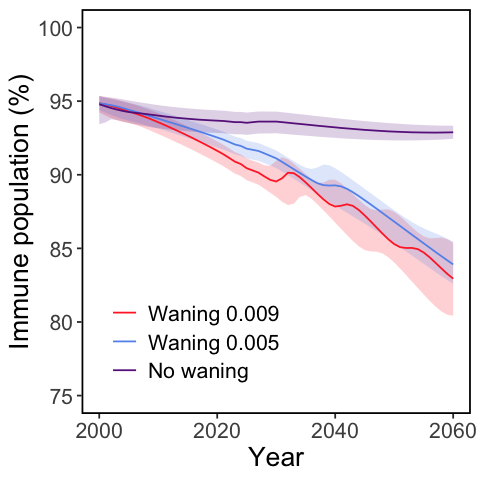

In [50]:
options(repr.plot.width = 4, repr.plot.height = 4)

pp<- plot_susceptibility_percentages_normal_vs_shift(df_susceptibility_perc, 
                                               uncertainty = df_wide)

#ggsave( "./figures/3_Flanders_figure2a.png", plot = pp, 
#       width = 4, height = 4, units = "in", dpi = 300)

pp

## Age-stratified immunity profiles

In [51]:
month = 1
day = 1

In [52]:
d1 <- plot_immunity_level(y_shift_2025[[1]], yts_begin, yts_end, 
                                   2005, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d2 <- plot_immunity_level(y_shift_2025[[1]], yts_begin, yts_end, 
                                   2025, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d3 <- plot_immunity_level(y_shift_2025[[1]], yts_begin, yts_end, 
                                   2045, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d4 <- plot_immunity_level(y_shift_2025_no_waning[[1]], yts_begin, yts_end, 
                                   2005, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d5 <- plot_immunity_level(y_shift_2025_no_waning[[1]], yts_begin, yts_end, 
                                   2025, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d6 <- plot_immunity_level(y_shift_2025_no_waning[[1]], yts_begin, yts_end, 
                                   2045, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d7 <- plot_immunity_level(y_shift_2025_fast_waning[[1]], yts_begin, yts_end, 
                                   2005, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d8 <- plot_immunity_level(y_shift_2025_fast_waning[[1]], yts_begin, yts_end, 
                                   2025, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

d9 <- plot_immunity_level(y_shift_2025_fast_waning[[1]], yts_begin, yts_end, 
                                   2045, month, day,
                                   age_cat_per_compartment)$dataset[1:80,]

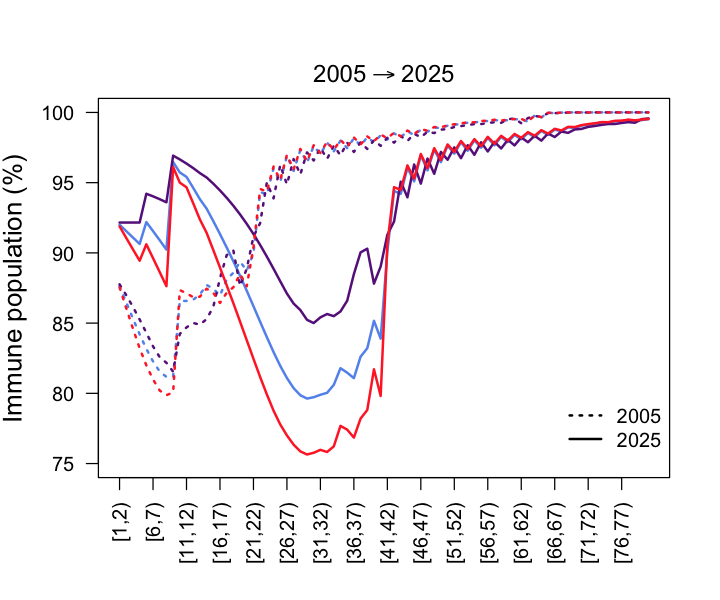

In [53]:
options(repr.plot.width = 6, repr.plot.height = 5)

#png("./figures/3_Flanders_figure2b_2025.png", width = 6, height = 5, units = "in", res = 300)

plot(seq_along(d1$age), d1$y_immune, type = "l", xlab = "", col = palette[2], lty = 3, 
     ylab = "", xaxt = "n", lwd=2, ylim = c(75, 100), las = 1)
mtext("Immune population (%)", side = 2, line = 3, cex = 1.3)
mtext(expression(2005 %->% 2025), side = 3, line = 0.5, cex = 1.2)

lines(seq_along(d2$age), d2$y_immune, col = palette[2], lwd=2, lty = 1)
#lines(seq_along(d3$age), d3$y_immune, col = palette[2], lwd=2.5, lty = 1)

lines(seq_along(d4$age), d4$y_immune, col = palette[3], lwd=2, lty = 3)
lines(seq_along(d5$age), d5$y_immune, col = palette[3], lwd=2, lty = 1)
#lines(seq_along(d6$age), d6$y_immune, col = palette[3], lwd=2.5, lty = 1)

lines(seq_along(d7$age), d7$y_immune, col = palette[1], lwd=2, lty = 3)
lines(seq_along(d8$age), d8$y_immune, col = palette[1], lwd=2, lty = 1)
#lines(seq_along(d9$age), d9$y_immune, col = palette[1], lwd=2.5, lty = 1)

# Show one x-axis label every 5 elements
tick_positions <- seq(1, length(d1$age), by = 5)

axis(1,
     at = tick_positions,
     labels = d1$age[tick_positions],
     las = 2,
     cex.axis = 1)

legend("bottomright",
       inset = c(0.01, 0.05),
       legend = c("2005", "2025"),
       col = "black",
       lty = c(3, 1),
       lwd = 2,
       y.intersp = 1.5,
       bty = "n")

#dev.off()

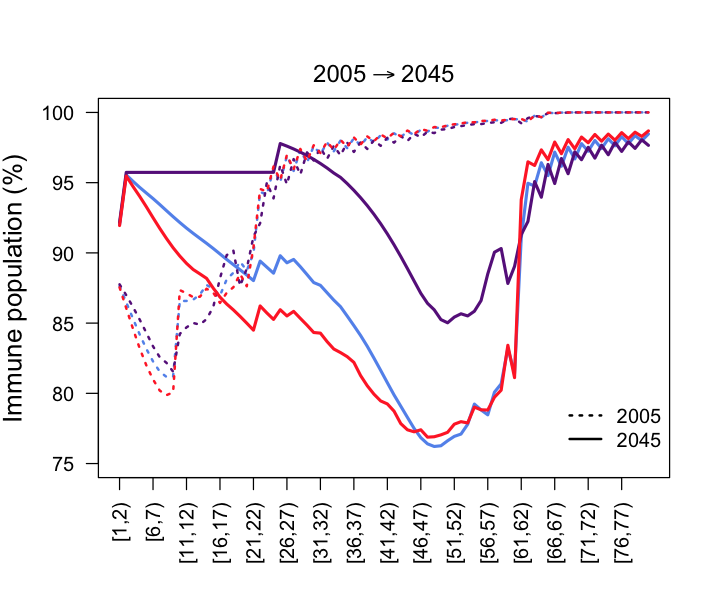

In [54]:
options(repr.plot.width = 6, repr.plot.height = 5)

#png("./figures/3_Flanders_figure2b_2045.png", width = 6, height = 5, units = "in", res = 300)

plot(seq_along(d1$age), d1$y_immune, type = "l", xlab = "", col = palette[2], lty = 3, 
     ylab = "", xaxt = "n", lwd=2, ylim = c(75, 100), las = 1)
mtext("Immune population (%)", side = 2, line = 3, cex = 1.3)
mtext(expression(2005 %->% 2045), side = 3, line = 0.5, cex = 1.2)

#lines(seq_along(d2$age), d2$y_immune, col = palette[2], lwd=2, lty = 2)
lines(seq_along(d3$age), d3$y_immune, col = palette[2], lwd=2.5, lty = 1)

lines(seq_along(d4$age), d4$y_immune, col = palette[3], lwd=2, lty = 3)
#lines(seq_along(d5$age), d5$y_immune, col = palette[3], lwd=2, lty = 2)
lines(seq_along(d6$age), d6$y_immune, col = palette[3], lwd=2.5, lty = 1)

lines(seq_along(d7$age), d7$y_immune, col = palette[1], lwd=2, lty = 3)
#lines(seq_along(d8$age), d8$y_immune, col = palette[1], lwd=2, lty = 2)
lines(seq_along(d9$age), d9$y_immune, col = palette[1], lwd=2.5, lty = 1)

# Show one x-axis label every 5 elements
tick_positions <- seq(1, length(d1$age), by = 5)

axis(1,
     at = tick_positions,
     labels = d1$age[tick_positions],
     las = 2,
     cex.axis = 1)

legend("bottomright",
       inset = c(0.01, 0.05),
       legend = c("2005", "2045"),
       col = "black",
       lty = c(3, 1),
       lwd = 2,
       y.intersp = 1.5,
       bty = "n")

#dev.off()

## Scenarios with vaccination schedule changes

In [55]:
list_year_plots <- c(2020:2050)

### (SKIP) run parallel simulations and save results

In [132]:
samples <- samples_lhratio_normalapprox

round(quantile(samples_lhratio_normalapprox, c(0.5,0.025,0.975)),2)
round(c(initial_params[length(initial_params)], 
  initial_params_CI_lo[length(initial_params)], 
  initial_params_CI_up[length(initial_params)]),3)

50%  2.5% 97.5% 
10.12  8.99 11.15

[1] 10.1  9.0 11.1

In [133]:
if (num_age_groups == 102) {
age_groups_to_plot <- list(
  "all" = c(1:102),
  "<1" = c(1:3),
  "1-4" = c(4:7),
  "5-9" = c(8:12),
  "10-19" = c(13:22),
  "20-49" = c(23:52),
  "50+" = c(53:102)
)
} else {
    stop("error, please revise the definition of the age groups")
}

## sortcut function to extract output of interest

extractTotalCases <- function(y_out, year_plot, selected_age_tag="all") {
    sum(calculate_newly_infectious_for_year(y_out, yts_begin, yts_end,  
                                            year_plot, age_cat_per_compartment, 
                                            selected_columns="NewlyInfectious_r", 
                                            selected_ages = age_groups_to_plot[[selected_age_tag]]))
    }

In [63]:
run_one_sample_scenarios03 <- function(jj) {

    list_year_plots <- c(2020:2050)

    R0_sample <- samples[jj]
    
    sample_params <- initial_params
    sample_params[length(initial_params)] <- R0_sample
    
    y_shift_2023 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2023)

    y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)

    y_shift_2025_hcov2 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_hcov2)
    
    y_shift_2025_lcov2 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_lcov2)

    #y_shift_2025_lcov1 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_lcov1)

    #y_shift_2025_9months <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_9months)
    
    #y_shift_2025_9months_immune_blunting <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_9months, 
                                                                   #immune_blunting = TRUE)

    #y_shift_2025_gradualcatchup30y40y_cov10 <- simulateModel_shortcut(sample_params, 
                                                                     # age_cat_to_vacc_shift_2025_gradualcatchup30y40y_10cov)

    # Store results locally
    results <- vector("list", 4)
    names(results) <- paste0("scen", 0:3)
    
    for (selected_age_tag in names(age_groups_to_plot)) {
    
            results$scen0[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen1[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen2[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen3[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen4[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen5[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen6[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen7[[selected_age_tag]] <- numeric(length(list_year_plots))

        for (i in seq_along(list_year_plots)) {

            year_plot <- list_year_plots[i]

            results$scen0[[selected_age_tag]][i] <- extractTotalCases(y_shift_2023, year_plot, selected_age_tag)
            results$scen1[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025, year_plot, selected_age_tag)
            results$scen2[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_hcov2, year_plot, selected_age_tag)
            results$scen3[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_lcov2, year_plot, selected_age_tag)
            #results$scen4[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_9months, year_plot, selected_age_tag)
            #results$scen5[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_9months_immune_blunting, year_plot, selected_age_tag)
            #results$scen6[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_gradualcatchup30y40y_cov10, year_plot, selected_age_tag)
            #results$scen7[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_lcov1, year_plot, selected_age_tag)

        }    
    }
    
    return(results)
}

In [64]:
Sys.time()

[1] "2026-10-18 22:15:08 CEST"

In [65]:
out <- mclapply(
    seq_along(samples[1:250]),
    run_one_sample_scenarios03,
    mc.cores = 10
)

#Reconstruct your original objects
outbreak_baseline <- lapply(out, function(x) x$scen0)
outbreak_scen1    <- lapply(out, function(x) x$scen1)
outbreak_scen2    <- lapply(out, function(x) x$scen2)
outbreak_scen3    <- lapply(out, function(x) x$scen3)
#outbreak_scen4    <- lapply(out, function(x) x$scen4)
#outbreak_scen5    <- lapply(out, function(x) x$scen5)
#outbreak_scen6    <- lapply(out, function(x) x$scen6)
#outbreak_scen7    <- lapply(out, function(x) x$scen7)

In [66]:
Sys.time()

[1] "2026-10-18 23:38:34 CEST"

In [67]:
run_one_sample_scenarios47 <- function(jj) {

    list_year_plots <- c(2020:2050)

    R0_sample <- samples[jj]
    
    sample_params <- initial_params
    sample_params[length(initial_params)] <- R0_sample
    
    #y_shift_2023 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2023)

    #y_shift_2025 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025)

    #y_shift_2025_hcov2 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_hcov2)
    
    #y_shift_2025_lcov2 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_lcov2)

    y_shift_2025_lcov1 <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_lcov1)

    y_shift_2025_9months <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_9months)
    
    y_shift_2025_9months_immune_blunting <- simulateModel_shortcut(sample_params, age_cat_to_vacc_shift_2025_9months, 
                                                                   immune_blunting = TRUE)

    y_shift_2025_gradualcatchup30y40y_cov10 <- simulateModel_shortcut(sample_params, 
                                                                      age_cat_to_vacc_shift_2025_gradualcatchup30y40y_10cov)

    # Store results locally
    results <- vector("list", 4)
    names(results) <- paste0("scen", 4:7)
    
    for (selected_age_tag in names(age_groups_to_plot)) {
    
            #results$scen0[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen1[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen2[[selected_age_tag]] <- numeric(length(list_year_plots))
            #results$scen3[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen4[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen5[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen6[[selected_age_tag]] <- numeric(length(list_year_plots))
            results$scen7[[selected_age_tag]] <- numeric(length(list_year_plots))

        for (i in seq_along(list_year_plots)) {

            year_plot <- list_year_plots[i]

            #results$scen0[[selected_age_tag]][i] <- extractTotalCases(y_shift_2023, year_plot, selected_age_tag)
            #results$scen1[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025, year_plot, selected_age_tag)
            #results$scen2[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_hcov2, year_plot, selected_age_tag)
            #results$scen3[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_lcov2, year_plot, selected_age_tag)
            results$scen4[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_lcov1, year_plot, selected_age_tag)
            results$scen5[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_9months, year_plot, selected_age_tag)
            results$scen6[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_9months_immune_blunting, year_plot, selected_age_tag)
            results$scen7[[selected_age_tag]][i] <- extractTotalCases(y_shift_2025_gradualcatchup30y40y_cov10, year_plot, selected_age_tag)

        }    
    }
    
    return(results)
}

In [68]:
out <- mclapply(
    seq_along(samples[1:250]),
    run_one_sample_scenarios47,
    mc.cores = 10
)

#Reconstruct your original objects
#outbreak_baseline <- lapply(out, function(x) x$scen0)
#outbreak_scen1    <- lapply(out, function(x) x$scen1)
#outbreak_scen2    <- lapply(out, function(x) x$scen2)
#outbreak_scen3    <- lapply(out, function(x) x$scen3)
outbreak_scen4    <- lapply(out, function(x) x$scen4)
outbreak_scen5    <- lapply(out, function(x) x$scen5)
outbreak_scen6    <- lapply(out, function(x) x$scen6)
outbreak_scen7    <- lapply(out, function(x) x$scen7)

In [ ]:
save(outbreak_baseline,
     outbreak_scen1,
     outbreak_scen2,
     outbreak_scen3,
     outbreak_scen4,
     outbreak_scen5,
     outbreak_scen6,
     outbreak_scen7,
     file = "./results/3c(updated)_Flanders_run_scenarios_Fig4_uncertainty.RData")

### read results

In [56]:
load("./results/3c(updated)_Flanders_run_scenarios_Fig4_uncertainty.RData")

In [57]:
list_year_plots <- c(2020:2050)

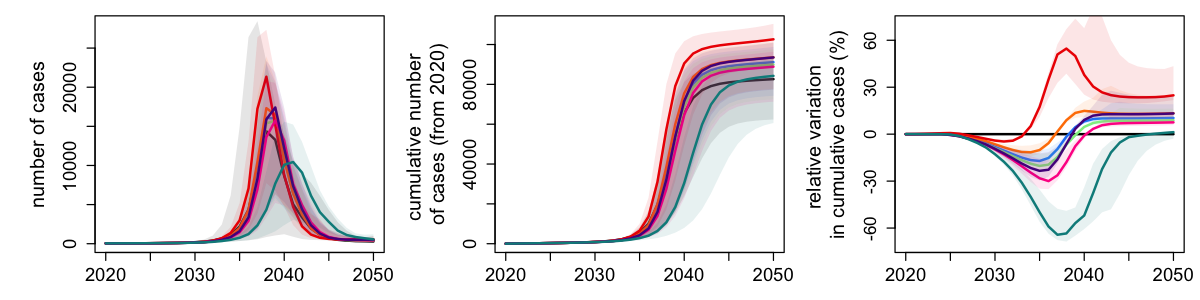

In [58]:
options(scipen = 999)

options(repr.plot.width = 10, repr.plot.height = 2.5)

layout(matrix(1:3, nrow=1, byrow=TRUE))

colors_survey <- c("black", "dodgerblue", 
                   "lightgreen", "darkorange1", "red2",
                   "deeppink", "purple4", "cyan4")

# yearly numbers
outbreak_scen <- outbreak_baseline
rel_var <- list()
for (jj in seq_along(outbreak_scen)) {
    rel_var[[jj]] <- outbreak_scen[[jj]][["all"]]
}

rel_var <- as.data.frame(do.call(rbind, rel_var))

medians <- apply(rel_var, 2, median, na.rm = TRUE)

par(mar=c(3,6,1,1))
plot(list_year_plots, medians, col=colors_survey[1], type = "o", pch = NA, lwd = 2, 
     ylim=c(0,28000),
     xlab="", ylab="\nnumber of cases",
     cex.lab = 1.5,
     cex.axis = 1.4)

x <- list_year_plots
y1 <- apply(rel_var, 2, quantile, probs = 0.975, na.rm = TRUE)
y2 <- apply(rel_var, 2, quantile, probs = 0.025, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(colors_survey[1], alpha.f = 0.1),
        border = NA)

for (scen in c(1:7)) {

    outbreak_scen <- list(outbreak_scen1, outbreak_scen2, outbreak_scen3,
                          outbreak_scen4, outbreak_scen5, outbreak_scen6, outbreak_scen7)[[scen]]

    rel_var <- list()
    for (jj in seq_along(outbreak_scen)) {
        rel_var[[jj]] <- outbreak_scen[[jj]][["all"]]
    }

    rel_var <- as.data.frame(do.call(rbind, rel_var))

    medians <- apply(rel_var, 2, median, na.rm = TRUE)
    
    lines(list_year_plots, medians, type = "o", , col=colors_survey[scen+1], pch = NA, lwd = 2)

    x <- list_year_plots
    y1 <- apply(rel_var, 2, quantile, probs = 0.75, na.rm = TRUE)
    y2 <- apply(rel_var, 2, quantile, probs = 0.25, na.rm = TRUE)
    polygon(x = c(x, rev(x)),
            y = c(y1, rev(y2)),
            col = adjustcolor(colors_survey[scen+1], alpha.f = 0.1),
            border = NA)
}

# cumulative numbers
outbreak_scen <- outbreak_baseline
rel_var <- list()
for (jj in seq_along(outbreak_scen)) {
    rel_var[[jj]] <- cumsum(outbreak_scen[[jj]][["all"]])
}

rel_var <- as.data.frame(do.call(rbind, rel_var))

medians <- apply(rel_var, 2, median, na.rm = TRUE)

plot(list_year_plots, medians, col=colors_survey[1], type = "o", pch = NA, lwd = 2,
     ylim=c(0,110000), 
     xlab="", ylab="cumulative number \nof cases (from 2020)",
     cex.lab = 1.5,
     cex.axis = 1.4)

x <- list_year_plots
y1 <- apply(rel_var, 2, quantile, probs = 0.75, na.rm = TRUE)
y2 <- apply(rel_var, 2, quantile, probs = 0.25, na.rm = TRUE)
polygon(x = c(x, rev(x)),
        y = c(y1, rev(y2)),
        col = adjustcolor(colors_survey[1], alpha.f = 0.1),
        border = NA)

for (scen in c(1:7)) {

    outbreak_scen <- list(outbreak_scen1, outbreak_scen2, outbreak_scen3,
                          outbreak_scen4, outbreak_scen5, outbreak_scen6, outbreak_scen7)[[scen]]

    rel_var <- list()
    for (jj in seq_along(outbreak_scen)) {
        rel_var[[jj]] <- cumsum(outbreak_scen[[jj]][["all"]])
    }

    rel_var <- as.data.frame(do.call(rbind, rel_var))

    medians <- apply(rel_var, 2, median, na.rm = TRUE)
    
    lines(list_year_plots, medians, type = "o", , col=colors_survey[scen+1], pch = NA, lwd = 2)

    x <- list_year_plots
    y1 <- apply(rel_var, 2, quantile, probs = 0.75, na.rm = TRUE)
    y2 <- apply(rel_var, 2, quantile, probs = 0.25, na.rm = TRUE)
    polygon(x = c(x, rev(x)),
            y = c(y1, rev(y2)),
            col = adjustcolor(colors_survey[scen+1], alpha.f = 0.1),
            border = NA)
}

# cumulative numbers - relative variation
plot(list_year_plots, rep(0, length(list_year_plots)), col=colors_survey[1], type = "l", lwd = 2,
     ylim=c(-70,70), 
     xlab="", 
     yaxt = "n",   # remove default y-axis
     ylab="relative variation \nin cumulative cases (%)",
     cex.lab = 1.5,
     cex.axis = 1.4)

axis(
  side = 2,
  at = seq(-60, 60, by = 30),
  cex.axis = 1.3
)

for (scen in c(1:7)) {

    outbreak_scen <- list(outbreak_scen1, outbreak_scen2, outbreak_scen3,
                          outbreak_scen4, outbreak_scen5, outbreak_scen6, outbreak_scen7)[[scen]]

    rel_var <- list()
    for (jj in seq_along(outbreak_scen)) {
        rel_var[[jj]] <- 100*(cumsum(outbreak_scen[[jj]][["all"]])-cumsum(outbreak_baseline[[jj]][["all"]]))/cumsum(outbreak_baseline[[jj]][["all"]])
    }

    rel_var <- as.data.frame(do.call(rbind, rel_var))

    medians <- apply(rel_var, 2, median, na.rm = TRUE)
    
    lines(list_year_plots, medians, type = "l", col=colors_survey[scen+1], pch = 16, lwd = 2)

    x <- list_year_plots
    y1 <- apply(rel_var, 2, quantile, probs = 0.75, na.rm = TRUE)
    y2 <- apply(rel_var, 2, quantile, probs = 0.25, na.rm = TRUE)
    polygon(x = c(x, rev(x)),
            y = c(y1, rev(y2)),
            col = adjustcolor(colors_survey[scen+1], alpha.f = 0.1),
            border = NA)

}

In [59]:
if (num_age_groups == 102) {
age_groups_to_plot <- list(
  "all" = c(1:102),
  "<1" = c(1:3),
  "1-4" = c(4:7),
  "5-9" = c(8:12),
  "10-19" = c(13:22),
  "20-49" = c(23:52),
  "50+" = c(53:102)
)
} else {
    stop("error, please revise the definition of the age groups")
}

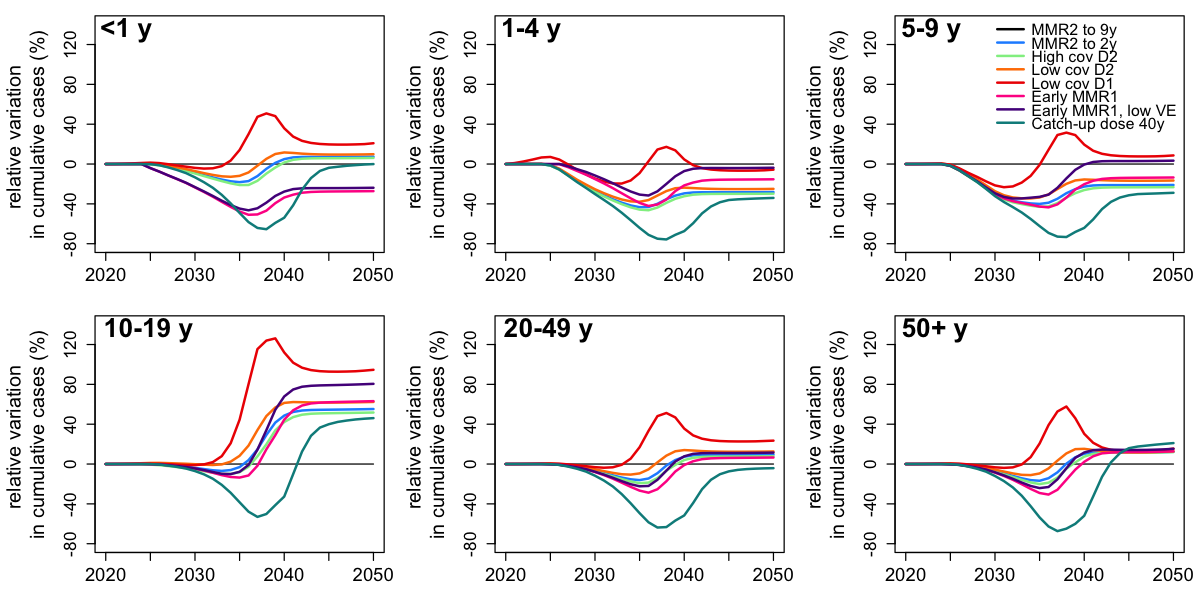

In [60]:
options(repr.plot.width = 10, repr.plot.height = 5)

layout(matrix(1:6, nrow=2, byrow=TRUE))

for (selected_age_tag in names(age_groups_to_plot)) {

    if (selected_age_tag != "all") {

    # first column: plots 1 and 4
    if (selected_age_tag %in% c("<1","10-19")) {
        par(mar=c(3,6,1,1))   # larger left margin
    } else {
        par(mar=c(3,6,1,1))   # smaller left margin
    }
    
    colors_survey <- c("black", "dodgerblue", 
                       "lightgreen", "darkorange1", "red2",
                       "deeppink", "purple4", "cyan4")

    # cumulative numbers
    plot(list_year_plots, rep(0, length(list_year_plots)), col=colors_survey[1], type = "l", pch = 16, 
         ylim=c(-80,140), 
         yaxt = "n",   # remove default y-axis
         xlab="", 
         #ylab=if (selected_age_tag %in% c("<1","10-19" )) "relative variation in cumulative cases (%)" else "")
         ylab="relative variation \nin cumulative cases (%)", 
         cex.lab = 1.5,
         cex.axis = 1.4)
         #main = paste(selected_age_tag, "y"))

    axis(
      side = 2,
      at = seq(-80, 140, by = 40),
      cex.axis = 1.3
    )

    text(
      x = par("usr")[1],   # left edge of plot region
      y = par("usr")[4],   # top edge of plot region
      labels = paste(selected_age_tag, "y"),
      adj = c(-0.1, 1.1),  # slight padding inward
      cex = 2,           # font size (increase this)
      font = 2             # bold
    )
    
    for (scen in c(1:7)) {

        outbreak_scen <- list(outbreak_scen1, outbreak_scen2, outbreak_scen3, 
                              outbreak_scen4, outbreak_scen5, outbreak_scen6, outbreak_scen7)[[scen]]

        rel_var <- list()
        for (jj in seq_along(outbreak_scen)) {
            rel_var[[jj]] <- 100*(cumsum(outbreak_scen[[jj]][[selected_age_tag]])-cumsum(outbreak_baseline[[jj]][[selected_age_tag]]))/cumsum(outbreak_baseline[[jj]][[selected_age_tag]])
        }
    
        rel_var <- as.data.frame(do.call(rbind, rel_var))
    
        medians <- apply(rel_var, 2, median, na.rm = TRUE)
        
        lines(list_year_plots, medians, type = "l", , col=colors_survey[scen+1], pch = 16, lwd = 2)
    
        x <- list_year_plots
        y1 <- apply(rel_var, 2, quantile, probs = 0.75, na.rm = TRUE)
        y2 <- apply(rel_var, 2, quantile, probs = 0.25, na.rm = TRUE)
        #polygon(x = c(x, rev(x)),
        #        y = c(y1, rev(y2)),
        #        col = adjustcolor(colors_survey[scen+1], alpha.f = 0.15),
        #        border = NA)

    }

    if (selected_age_tag == "5-9") {
            legend(
              "topright",
              inset = c(-0.45, 0),
              legend = c("MMR2 to 9y", "MMR2 to 2y", 
                                     "High cov D2", 
                                     "Low cov D2", 
                                     "Low cov D1",
                                     "Early MMR1", 
                                     "Early MMR1, low VE",
                                     "Catch-up dose 40y"),
              col = colors_survey,
              lty = 1,
              pch = NA,
              pt.cex = 1.4,
              cex = 1.2,
              lwd = 2,
              y.intersp = 1.,   # increase vertical spacing
              x.intersp = 0.3,
              seg.len = 1,
              bty = "n"
            )

    }

  }
}